# Seismic Horizon Detection on the Netherlands F3 Dataset
**ARTI 403 – Image Processing, 7FS1 Group 4**

Pipeline: **enhancement → noise reduction → edge detection → morphological post-processing**, evaluated against the
interpreted horizons of the F3 dataset (Silva et al., 2019) and on synthetic Ricker-wavelet sections.

**How to run:** `Runtime → Run all`. The first run downloads about 1.3 GB from Zenodo into your Google Drive
(`MyDrive/F3_dataset/`). Later runs reuse it. If you already uploaded `inlines.zip`, `crosslines.zip` and
`masks.tar.gz` to that folder yourself, the download is skipped.

A CPU runtime is enough, no GPU needed. A full run takes roughly 15–30 minutes, mostly the parameter search.
Set `QUICK = True` in the next cell for a fast test run (about 5 minutes).

In [ ]:
# ============================ 1. Setup & configuration ============================
!pip -q install tifffile

import os, sys, time, json, zipfile, tarfile, urllib.request, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tifffile
from skimage import io as skio
from scipy import ndimage as ndi

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---- paths: change DRIVE_DIR if your data lives somewhere else in Drive ----
DRIVE_DIR   = '/content/drive/MyDrive/F3_dataset' if IN_COLAB else os.path.abspath('F3_dataset')
LOCAL_DIR   = '/content/f3' if IN_COLAB else os.path.abspath('f3_local')   # fast local disk
RESULTS_DIR = os.path.join(DRIVE_DIR, 'results')
for d in (DRIVE_DIR, LOCAL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

QUICK = False        # True = fewer sections, for a fast test run
TOL   = 3            # tolerance radius in pixels (3 px = +-12 ms at 4 ms sampling)
ENH   = dict(agc_win=31, use_clahe=False)   # enhancement settings used for all configurations

# ---- sections: tuning and test sets, spaced so neighbouring (near-identical) sections never mix ----
TUNE = {'inline': list(range(125, 751, 100)), 'crossline': list(range(350, 1251, 150))}
TEST = {'inline': list(range(150, 751, 50)),  'crossline': list(range(425, 1251, 100))}
if QUICK:
    TUNE = {k: v[::2] for k, v in TUNE.items()}
    TEST = {k: v[::3] for k, v in TEST.items()}

for kind in TUNE:
    gap = min(abs(a - b) for a in TUNE[kind] for b in TEST[kind])
    assert gap >= 10, f'{kind}: tuning and test sections only {gap} apart'
print('tuning sections:', TUNE, '\ntest sections:  ', TEST)

Mounted at /content/drive
tuning sections: {'inline': [125, 225, 325, 425, 525, 625, 725], 'crossline': [350, 500, 650, 800, 950, 1100, 1250]} 
test sections:   {'inline': [150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750], 'crossline': [425, 525, 625, 725, 825, 925, 1025, 1125, 1225]}


## 2. Get the data
Downloads only the three files we need (`inlines.zip`, `crosslines.zip`, `masks.tar.gz`) from
[Zenodo record 1471548](https://zenodo.org/records/1471548) into Drive, then extracts **only the selected
sections** to the fast local disk.

In [ ]:
ZENODO_API = 'https://zenodo.org/api/records/1471548'
NEEDED = ['inlines.zip', 'crosslines.zip', 'masks.tar.gz']

def tiff_path(kind, n): return os.path.join(LOCAL_DIR, f'{kind}s', f'{kind}_{n}.tiff')
def mask_path(kind, n): return os.path.join(LOCAL_DIR, 'masks', f'{kind}_{n}_mask.png')

wanted = [(k, n) for sets in (TUNE, TEST) for k, ns in sets.items() for n in ns]
missing = [(k, n) for k, n in wanted if not (os.path.exists(tiff_path(k, n)) and os.path.exists(mask_path(k, n)))]

def download(url, size, dest):
    tmp = dest + '.part'
    with urllib.request.urlopen(url) as r, open(tmp, 'wb') as out:
        done = 0
        while True:
            chunk = r.read(1 << 22)
            if not chunk:
                break
            out.write(chunk); done += len(chunk)
            print(f'\r  {os.path.basename(dest)}: {done/1e6:6.0f} / {size/1e6:.0f} MB', end='')
    print()
    os.replace(tmp, dest)

if not missing:
    print('All selected sections already extracted - nothing to download.')
else:
    files = {f['key']: f for f in json.load(urllib.request.urlopen(ZENODO_API))['files']}
    for key in NEEDED:
        dest = os.path.join(DRIVE_DIR, key)
        if os.path.exists(dest) and os.path.getsize(dest) == files[key]['size']:
            print(f'{key}: found in Drive')
        else:
            print(f'{key}: downloading from Zenodo into Drive ...')
            download(files[key]['links']['self'], files[key]['size'], dest)

    with tarfile.open(os.path.join(DRIVE_DIR, 'masks.tar.gz')) as t:
        try:
            t.extractall(LOCAL_DIR, filter='data')
        except TypeError:                      # older Python without the filter argument
            t.extractall(LOCAL_DIR)
    for kind in ('inline', 'crossline'):
        with zipfile.ZipFile(os.path.join(DRIVE_DIR, f'{kind}s.zip')) as z:
            for k, n in missing:
                if k == kind and not os.path.exists(tiff_path(k, n)):
                    z.extract(f'{kind}s/{kind}_{n}.tiff', LOCAL_DIR)
    print(f'Extracted {len(missing)} sections to {LOCAL_DIR}')

inlines.zip: downloading from Zenodo into Drive ...
  inlines.zip:    637 / 637 MB
crosslines.zip: downloading from Zenodo into Drive ...
  crosslines.zip:    639 / 639 MB
masks.tar.gz: downloading from Zenodo into Drive ...
  masks.tar.gz:      5 / 5 MB
Extracted 36 sections to /content/f3


## 3. Pipeline module
All image-processing code is in `horizons.py`, written out by the next cell, so it can also be submitted as
source code. Sections inside the file: enhancement, noise filters, detectors, morphology, ground truth,
synthetic data, metrics.

In [ ]:
%%writefile horizons.py
"""
Seismic horizon detection pipeline (ARTI 403, Group 4).

Stages: enhancement -> noise reduction -> edge detection -> morphology,
plus ground-truth extraction, synthetic data and evaluation metrics.

Every stage function takes a 2D float32 array and returns a 2D array.
"""
import time

import numpy as np
from scipy import ndimage as ndi
from skimage import draw, exposure, feature, measure, morphology

# =============================================================================
# Stage 1: enhancement
# =============================================================================


def normalize(img, clip_pct=99.0):
    """Centre amplitudes on zero and scale to [-1, 1], clipping outliers.

    Works for float amplitudes and for 8-bit images where mid-grey = zero.
    """
    x = img.astype(np.float32)
    x = x - np.median(x)
    s = np.percentile(np.abs(x), clip_pct)
    return np.clip(x / (s + 1e-9), -1, 1).astype(np.float32)


def agc(x, win=31):
    """Automatic gain control: divide by RMS amplitude in a vertical window."""
    power = ndi.uniform_filter1d(x ** 2, size=win, axis=0, mode="reflect")
    rms = np.sqrt(np.maximum(power, 0)) + 1e-3  # rounding can make power slightly negative
    return normalize(x / rms)


def clahe(x, clip_limit=0.01):
    y = exposure.equalize_adapthist((x + 1) / 2, clip_limit=clip_limit)
    return (2 * y - 1).astype(np.float32)


def enhance(img, agc_win=31, use_clahe=False):
    x = normalize(img)
    if agc_win:
        x = agc(x, agc_win)
    if use_clahe:
        x = clahe(x)
    return x


# =============================================================================
# Stage 2: noise reduction
# =============================================================================


def f_none(x):
    return x


def f_gaussian(x, sigma=1.0):
    return ndi.gaussian_filter(x, sigma)


def f_median(x, size=3):
    return ndi.median_filter(x, size=size)


def f_anisotropic(x, n_iter=20, kappa_pct=80, lam=0.2):
    """Perona-Malik anisotropic diffusion (exponential conductance).

    kappa is set from the kappa_pct percentile of the neighbour differences,
    so it adapts to each section's amplitude range.
    """
    u = x.astype(np.float32).copy()
    g = np.abs(np.diff(u, axis=0))
    kappa = np.percentile(g, kappa_pct) + 1e-6
    for _ in range(n_iter):
        p = np.pad(u, 1, mode="edge")
        dN = p[:-2, 1:-1] - u
        dS = p[2:, 1:-1] - u
        dE = p[1:-1, 2:] - u
        dW = p[1:-1, :-2] - u
        u = u + lam * (np.exp(-(dN / kappa) ** 2) * dN + np.exp(-(dS / kappa) ** 2) * dS
                       + np.exp(-(dE / kappa) ** 2) * dE + np.exp(-(dW / kappa) ** 2) * dW)
    return u


FILTERS = {"none": f_none, "gaussian": f_gaussian, "median": f_median, "anisotropic": f_anisotropic}

# =============================================================================
# Stage 3: edge detection  (all return a boolean edge map)
# =============================================================================


def _vertical_nms(m):
    """Keep pixels that are >= their upper and lower neighbours (horizons are sub-horizontal)."""
    up = np.vstack([m[:1], m[:-1]])
    down = np.vstack([m[1:], m[-1:]])
    return (m >= up) & (m >= down)


def d_sobel(x, top_pct=10, mode="vertical"):
    """Sobel gradient, vertical non-maximum suppression, keep the strongest top_pct %."""
    gy = ndi.sobel(x, axis=0)
    if mode == "vertical":
        m = np.abs(gy)
    else:
        m = np.hypot(gy, ndi.sobel(x, axis=1))
    thr = np.percentile(m, 100 - top_pct)
    return _vertical_nms(m) & (m > thr)


def d_canny(x, sigma=2.0, low_q=0.7, high_q=0.9):
    return feature.canny(x, sigma=sigma, low_threshold=low_q, high_threshold=high_q,
                         use_quantiles=True)


def d_dog(x, sigma=1.5, k=1.6, top_pct=10, polarity="both"):
    """Difference of Gaussians ridge detector.

    D = G(sigma) - G(k*sigma) is large on bright ridges (amplitude peaks) and
    very negative on troughs. We keep vertical local maxima of D (peaks) and/or
    of -D (troughs) above a percentile threshold.
    """
    D = ndi.gaussian_filter(x, sigma) - ndi.gaussian_filter(x, k * sigma)
    out = np.zeros(x.shape, bool)
    for sign, name in ((1, "peak"), (-1, "trough")):
        if polarity in (name, "both"):
            r = sign * D
            thr = np.percentile(r, 100 - top_pct)
            out |= _vertical_nms(r) & (r > thr)
    return out


DETECTORS = {"sobel": d_sobel, "canny": d_canny, "dog": d_dog}

# =============================================================================
# Stage 4: morphological post-processing
# =============================================================================


def line_se(length, angle_deg):
    """Line-shaped structuring element of given length and angle (0 = horizontal)."""
    c = length // 2
    a = np.deg2rad(angle_deg)
    dx, dy = c * np.cos(a), c * np.sin(a)
    se = np.zeros((length, length), bool)
    rr, cc = draw.line(int(round(c + dy)), int(round(c - dx)), int(round(c - dy)), int(round(c + dx)))
    se[rr, cc] = True
    return se


def _neighbours(bw):
    k = np.ones((3, 3), int)
    k[1, 1] = 0
    return ndi.convolve(bw.astype(int), k, mode="constant")


def prune_spurs(skel, n=5):
    """Remove side branches shorter than n pixels from a skeleton."""
    pruned = skel.copy()
    for _ in range(n):
        ends = pruned & (_neighbours(pruned) <= 1)
        pruned &= ~ends
    # grow back the main lines from their (new) endpoints, along the original skeleton
    grow = pruned & (_neighbours(pruned) == 1)
    for _ in range(n):
        grow = ndi.binary_dilation(grow, np.ones((3, 3), bool)) & skel
    return pruned | grow


def directional_closing(bw, length=11, angles=(-10, 0, 10)):
    pad = length
    p = np.pad(bw, pad)
    out = p.copy()
    for a in angles:
        out |= ndi.binary_closing(p, structure=line_se(length, a))
    return out[pad:-pad, pad:-pad]


def postprocess(bw, length=11, angles=(-10, 0, 10), min_size=10, prune=5,
                min_extent=30, max_angle=30):
    """Directional closing -> skeleton -> spur pruning -> geometric filtering."""
    bw = morphology.remove_small_objects(bw, min_size=min_size, connectivity=2)
    bw = directional_closing(bw, length, angles)
    sk = morphology.skeletonize(bw)
    sk = prune_spurs(sk, prune)
    lab = measure.label(sk, connectivity=2)
    keep = np.zeros(lab.max() + 1, bool)
    for r in measure.regionprops(lab):
        minr, minc, maxr, maxc = r.bbox
        extent = maxc - minc
        # skimage orientation: angle between row axis and major axis; horizontal line -> +-90 deg
        tilt = 90 - abs(np.rad2deg(r.orientation))
        keep[r.label] = extent >= min_extent and tilt <= max_angle
    return keep[lab]


# =============================================================================
# Full pipeline
# =============================================================================


def run_pipeline(img, enh=None, filt=("none", {}), det=("canny", {}), morph=None, already_enhanced=False):
    """Run one configuration. Returns (edge_map, timings_in_seconds)."""
    t = {}
    t0 = time.perf_counter()
    x = img if already_enhanced else enhance(img, **(enh or {}))
    t["enhance"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    x = FILTERS[filt[0]](x, **filt[1])
    t["filter"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    e = DETECTORS[det[0]](x, **det[1])
    t["detect"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    if morph is not None:
        e = postprocess(e, **morph)
    t["morph"] = time.perf_counter() - t0
    t["total"] = sum(t.values())
    return e, t


# =============================================================================
# Ground truth
# =============================================================================


def flat_boundaries(lbl):
    """Boundary ids whose depth is identical in every column (artificial, not interpreted).

    In the F3 masks the boundaries into labels 1 and 2 sit at rows 18 and 38 in
    every section, so they are almost certainly not real interpreted horizons.
    """
    lbl = np.asarray(lbl)
    flat = []
    for k in range(1, int(lbl.max()) + 1):
        cols = lbl.max(axis=0) >= k
        if cols.sum() < 2:
            continue
        rows = np.argmax(lbl[:, cols] >= k, axis=0)
        if rows.min() == rows.max():
            flat.append(k)
    return flat


def gt_from_mask(lbl, exclude_flat=True):
    """Horizon lines from an interval-label mask (labels increase downwards).

    A horizon pixel is where the label changes going down a column.
    Returns (gt_bool, horizon_id): horizon_id[r, c] = k for the boundary into
    label k (B1 = shallowest ... B9 = deepest), 0 where there is no boundary.
    """
    lbl = np.asarray(lbl)
    change = np.zeros(lbl.shape, bool)
    change[:-1] = lbl[:-1] != lbl[1:]
    hid = np.zeros(lbl.shape, np.int32)
    hid[:-1][change[:-1]] = lbl[1:][change[:-1]].astype(np.int32)
    if exclude_flat:
        for k in flat_boundaries(lbl):
            change[hid == k] = False
            hid[hid == k] = 0
    return change, hid


# =============================================================================
# Synthetic data (Ricker convolution model)
# =============================================================================


def ricker(freq=30.0, dt=0.004, length=0.2):
    t = np.arange(-length / 2, length / 2 + dt, dt)
    a = (np.pi * freq * t) ** 2
    return ((1 - 2 * a) * np.exp(-a)).astype(np.float32)


def make_synthetic(h=300, w=600, n_interfaces=8, freq=30.0, dt=0.004, snr=None, seed=0):
    """2D synthetic seismic section with gently folded/dipping interfaces.

    snr = signal RMS / noise RMS (None = noise free).
    Returns (image, gt_bool, label_mask).
    """
    rng = np.random.default_rng(seed)
    cols = np.arange(w)
    margin = 20
    base = np.linspace(margin, h - margin, n_interfaces)
    rows = []
    for b in base:
        dip = rng.uniform(-0.03, 0.03)
        amp = rng.uniform(0, 8)
        wavelen = rng.uniform(200, 600)
        phase = rng.uniform(0, 2 * np.pi)
        rows.append(b + dip * (cols - w / 2) + amp * np.sin(2 * np.pi * cols / wavelen + phase))
    rows = np.sort(np.round(np.array(rows)).astype(int), axis=0)
    for i in range(1, n_interfaces):  # keep interfaces at least 6 px apart
        rows[i] = np.maximum(rows[i], rows[i - 1] + 6)
    rows = np.clip(rows, 1, h - 2)

    imp = rng.uniform(2.0, 6.0, n_interfaces + 1)  # acoustic impedance per layer
    lbl = np.zeros((h, w), np.int32)
    refl = np.zeros((h, w), np.float32)
    r_idx = np.arange(h)[:, None]
    for i in range(n_interfaces):
        lbl[r_idx > rows[i][None, :]] = i + 1
        refl[rows[i], cols] = (imp[i + 1] - imp[i]) / (imp[i + 1] + imp[i])

    wav = ricker(freq, dt)
    img = ndi.convolve1d(refl, wav, axis=0, mode="constant")
    if snr is not None:
        sig_rms = np.sqrt(np.mean(img ** 2))
        img = img + rng.normal(0, sig_rms / snr, img.shape).astype(np.float32)
    gt, _ = gt_from_mask(lbl, exclude_flat=False)
    return img.astype(np.float32), gt, lbl


# =============================================================================
# Evaluation
# =============================================================================


def valid_region(gt, tol=3):
    """Rows between the top and bottom ground-truth horizon of each column (+- tol)."""
    h, w = gt.shape
    has = gt.any(axis=0)
    top = np.where(has, gt.argmax(axis=0), h)
    bot = np.where(has, h - 1 - gt[::-1].argmax(axis=0), -1)
    r = np.arange(h)[:, None]
    return (r >= top[None, :] - tol) & (r <= bot[None, :] + tol)


def evaluate(det, gt, hid=None, tol=3, comp_match=0.5, ci_extent=50):
    """Pixel P/R/F1 with tolerance, component precision, continuity index, per-horizon coverage.

    Precision is computed only inside the interpreted region (between the top and
    bottom horizon of each column), because detections outside it cannot be judged.
    """
    det = det & valid_region(gt, tol)
    dt_gt = ndi.distance_transform_edt(~gt)
    dt_det = ndi.distance_transform_edt(~det) if det.any() else np.full(gt.shape, np.inf)

    n_det = det.sum()
    P = float((dt_gt[det] <= tol).mean()) if n_det else 0.0
    R = float((dt_det[gt] <= tol).mean()) if gt.any() else 0.0
    F1 = 2 * P * R / (P + R) if P + R > 0 else 0.0

    lab = measure.label(det, connectivity=2)
    n_comp = lab.max()
    if n_comp:
        hit = ndi.mean((dt_gt <= tol).astype(float), labels=lab, index=np.arange(1, n_comp + 1))
        comp_P = float((np.asarray(hit) >= comp_match).mean())
        sl = ndi.find_objects(lab)
        extents = np.array([s[1].stop - s[1].start for s in sl])
        sizes = np.bincount(lab.ravel())[1:]
        CI = float(sizes[extents >= ci_extent].sum() / sizes.sum())
    else:
        comp_P, CI = 0.0, 0.0

    out = {"precision": P, "recall": R, "f1": F1, "comp_precision": comp_P,
           "continuity": CI, "n_components": int(n_comp)}
    if hid is not None:
        for h_id in np.unique(hid[hid > 0]):
            m = hid == h_id
            out[f"cov_B{h_id}"] = float((dt_det[m] <= tol).mean())
    return out

Writing horizons.py


In [ ]:
import horizons as H
importlib.reload(H)

def load(kind, n):
    img = tifffile.imread(tiff_path(kind, n)).astype(np.float32)
    lbl = skio.imread(mask_path(kind, n))
    gt, hid = H.gt_from_mask(lbl, exclude_flat=True)
    return dict(name=f'{kind}_{n}', kind=kind, img=img, lbl=lbl, gt=gt, hid=hid,
                enh=H.enhance(img, **ENH), flat=H.flat_boundaries(lbl))

tune_set = [load(k, n) for k, ns in TUNE.items() for n in ns]
test_set = [load(k, n) for k, ns in TEST.items() for n in ns]
s0 = tune_set[0]
print(f'{len(tune_set)} tuning + {len(test_set)} test sections loaded')
print('image', s0['img'].shape, s0['img'].dtype, '| labels', np.unique(s0['lbl']))
print('flat (artificial) boundaries excluded from ground truth:', sorted({b for s in tune_set + test_set for b in s['flat']}))
print('boundaries evaluated:', sorted(np.unique(np.concatenate([np.unique(s['hid']) for s in tune_set]))[1:]))

14 tuning + 22 test sections loaded
image (462, 951) float32 | labels [0 1 2 3 4 5 6 7 8 9]
flat (artificial) boundaries excluded from ground truth: [1, 2]
boundaries evaluated: [np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9)]


## 4. Sanity check: do the interpreted horizons sit on reflectors?
The F3 horizons were picked to separate **seismic facies**, not to follow individual reflectors (Silva et al., 2019).
Boundaries B1…B9 are numbered shallow → deep. The `strength` column below is the peak |amplitude| within ±2 samples
of each horizon, divided by the same quantity averaged over the section. Values clearly above 1 mean the horizon follows a
strong reflector (edge detection should find it). Values around 1 mean the horizon is a texture boundary (expect low coverage).

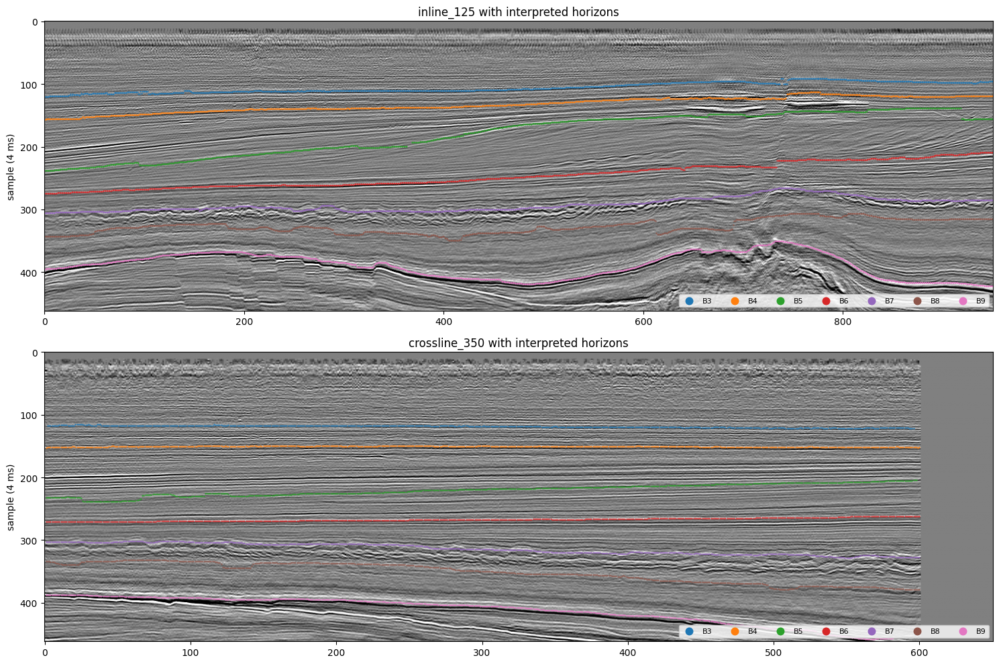

,mean,std
boundary,,
B3,1.22,0.21
B4,1.15,0.24
B5,1.13,0.20
B6,1.20,0.26
B7,1.22,0.20
B8,1.07,0.15
B9,1.16,0.18


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))
for ax, s in zip(axes, [tune_set[0], tune_set[len(TUNE['inline'])]]):
    v = np.percentile(np.abs(s['img']), 99)
    ax.imshow(s['img'], cmap='gray', vmin=-v, vmax=v, aspect='auto')
    for k in np.unique(s['hid'][s['hid'] > 0]):
        r, c = np.nonzero(s['hid'] == k)
        ax.scatter(c, r, s=0.4, label=f'B{k}')
    ax.set_title(f"{s['name']} with interpreted horizons"); ax.set_ylabel('sample (4 ms)')
    ax.legend(markerscale=12, ncol=9, fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_gt_overlay.png'), dpi=150); plt.show()

rows = []
for s in tune_set:
    peak = ndi.maximum_filter(np.abs(s['enh']), size=(5, 1))
    for k in np.unique(s['hid'][s['hid'] > 0]):
        rows.append(dict(boundary=f'B{k}', strength=peak[s['hid'] == k].mean() / peak.mean()))
strength = pd.DataFrame(rows).groupby('boundary').strength.agg(['mean', 'std']).round(2)
strength.to_csv(os.path.join(RESULTS_DIR, 'horizon_strength.csv')); strength

## 5. Parameter tuning (on tuning sections only)
**Stage A:** every noise filter setting × every detector setting, without morphology. For each
(filter, detector) pair we keep the setting with the highest mean F1.
**Stage B:** morphology parameters for each of the 12 best (filter, detector) pairs.
This gives 12 × {without, with} morphology = **24 configurations**, which are then run once on the test set.

In [ ]:
FILTER_GRID = {
    'none':        [{}],
    'gaussian':    [{'sigma': s} for s in (1.0, 1.5, 2.0)],
    'median':      [{'size': s} for s in (3, 5)],
    'anisotropic': [{'n_iter': n, 'kappa_pct': k} for n in (10, 20, 30) for k in (70, 90)],
}
DETECTOR_GRID = {
    'sobel': [{'top_pct': p, 'mode': m} for p in (5, 10, 15, 20) for m in ('vertical', 'magnitude')],
    'canny': [{'sigma': s, 'low_q': l, 'high_q': h} for s in (1.0, 2.0, 3.0)
              for l, h in ((0.6, 0.85), (0.7, 0.9), (0.8, 0.95))],
    'dog':   [{'sigma': s, 'top_pct': p, 'polarity': pol} for s in (1.0, 1.5, 2.0)
              for p in (5, 10, 15) for pol in ('peak', 'trough', 'both')],
}
MORPH_GRID = [{'length': L, 'angles': A, 'min_extent': me}
              for L in (7, 11, 15, 21)
              for A in ((0,), (-10, 0, 10), (-15, -10, -5, 0, 5, 10, 15))
              for me in (15, 30)]
METRICS = ['precision', 'recall', 'f1', 'comp_precision', 'continuity']

def mean_scores(edge_maps, sections):
    return pd.DataFrame([H.evaluate(e, s['gt'], s['hid'], tol=TOL) for e, s in zip(edge_maps, sections)])[METRICS].mean()

n_total = sum(len(f) for f in FILTER_GRID.values()) * sum(len(d) for d in DETECTOR_GRID.values())
print(f'Stage A: {n_total} filter x detector settings on {len(tune_set)} sections')
t0, rows = time.time(), []
for fname, fgrid in FILTER_GRID.items():
    for fp in fgrid:
        filtered = [H.FILTERS[fname](s['enh'], **fp) for s in tune_set]
        for dname, dgrid in DETECTOR_GRID.items():
            for dp in dgrid:
                m = mean_scores([H.DETECTORS[dname](x, **dp) for x in filtered], tune_set)
                rows.append(dict(filter=fname, fparams=fp, detector=dname, dparams=dp, **m))
        print(f'  {fname} {fp} done  ({time.time()-t0:.0f} s)')
tuneA = pd.DataFrame(rows)
best_base = tuneA.loc[tuneA.groupby(['filter', 'detector'])['f1'].idxmax()].reset_index(drop=True)
best_base[['filter', 'fparams', 'detector', 'dparams'] + METRICS].round(3)

Stage A: 528 filter x detector settings on 14 sections
  none {} done  (78 s)
  gaussian {'sigma': 1.0} done  (147 s)
  gaussian {'sigma': 1.5} done  (211 s)
  gaussian {'sigma': 2.0} done  (275 s)
  median {'size': 3} done  (342 s)
  median {'size': 5} done  (411 s)
  anisotropic {'n_iter': 10, 'kappa_pct': 70} done  (479 s)
  anisotropic {'n_iter': 10, 'kappa_pct': 90} done  (544 s)
  anisotropic {'n_iter': 20, 'kappa_pct': 70} done  (609 s)
  anisotropic {'n_iter': 20, 'kappa_pct': 90} done  (677 s)
  anisotropic {'n_iter': 30, 'kappa_pct': 70} done  (744 s)
  anisotropic {'n_iter': 30, 'kappa_pct': 90} done  (810 s)


,filter,fparams,detector,dparams,precision,recall,f1,comp_precision,continuity
0,anisotropic,"{'n_iter': 10, 'kappa_pct': 90}",canny,"{'sigma': 1.0, 'low_q': 0.8, 'high_q': 0.95}",0.263,0.593,0.363,0.231,0.705
1,anisotropic,"{'n_iter': 20, 'kappa_pct': 90}",dog,"{'sigma': 1.5, 'top_pct': 10, 'polarity': 'peak'}",0.332,0.565,0.417,0.223,0.476
2,anisotropic,"{'n_iter': 10, 'kappa_pct': 90}",sobel,"{'top_pct': 10, 'mode': 'magnitude'}",0.254,0.590,0.353,0.206,0.352
3,gaussian,{'sigma': 2.0},canny,"{'sigma': 1.0, 'low_q': 0.8, 'high_q': 0.95}",0.294,0.503,0.370,0.264,0.753
4,gaussian,{'sigma': 1.0},dog,"{'sigma': 2.0, 'top_pct': 5, 'polarity': 'peak'}",0.372,0.459,0.410,0.267,0.290
5,gaussian,{'sigma': 2.0},sobel,"{'top_pct': 10, 'mode': 'magnitude'}",0.287,0.527,0.370,0.223,0.393
6,median,{'size': 3},canny,"{'sigma': 2.0, 'low_q': 0.8, 'high_q': 0.95}",0.288,0.522,0.370,0.260,0.731
7,median,{'size': 3},dog,"{'sigma': 2.0, 'top_pct': 5, 'polarity': 'peak'}",0.360,0.476,0.409,0.258,0.259
8,median,{'size': 5},sobel,"{'top_pct': 10, 'mode': 'magnitude'}",0.239,0.665,0.351,0.199,0.105
9,none,{},canny,"{'sigma': 2.0, 'low_q': 0.8, 'high_q': 0.95}",0.285,0.554,0.375,0.249,0.730


In [ ]:
print(f'Stage B: {len(MORPH_GRID)} morphology settings x {len(best_base)} pairs')
t0, rows = time.time(), []
for _, b in best_base.iterrows():
    edges = [H.DETECTORS[b['detector']](H.FILTERS[b['filter']](s['enh'], **b['fparams']), **b['dparams'])
             for s in tune_set]
    for mp in MORPH_GRID:
        m = mean_scores([H.postprocess(e, **mp) for e in edges], tune_set)
        rows.append(dict(filter=b['filter'], detector=b['detector'], mparams=mp, length=mp['length'],
                         angles=str(mp['angles']), min_extent=mp['min_extent'], **m))
    print(f"  {b['filter']}+{b['detector']} done  ({time.time()-t0:.0f} s)")
tuneB = pd.DataFrame(rows)
best_morph = tuneB.loc[tuneB.groupby(['filter', 'detector'])['f1'].idxmax()].reset_index(drop=True)

CONFIGS = []
for _, b in best_base.iterrows():
    mp = best_morph[(best_morph['filter'] == b['filter']) & (best_morph['detector'] == b['detector'])].iloc[0]['mparams']
    for use_m in (False, True):
        CONFIGS.append(dict(name=f"{b['filter']}+{b['detector']}" + ('+morph' if use_m else ''),
                            filter=b['filter'], fparams=b['fparams'], detector=b['detector'],
                            dparams=b['dparams'], morph=mp if use_m else None))

for df, fn in ((tuneA, 'tuning_stageA.csv'), (tuneB, 'tuning_stageB.csv')):
    df.astype({c: str for c in df.columns if df[c].dtype == object}).to_csv(os.path.join(RESULTS_DIR, fn), index=False)
json.dump(CONFIGS, open(os.path.join(RESULTS_DIR, 'configs.json'), 'w'), indent=1)
best_morph[['filter', 'detector', 'length', 'angles', 'min_extent'] + METRICS].round(3)

Stage B: 24 morphology settings x 12 pairs
  anisotropic+canny done  (106 s)
  anisotropic+dog done  (211 s)
  anisotropic+sobel done  (319 s)
  gaussian+canny done  (423 s)
  gaussian+dog done  (519 s)
  gaussian+sobel done  (626 s)
  median+canny done  (740 s)
  median+dog done  (849 s)
  median+sobel done  (973 s)
  none+canny done  (1083 s)
  none+dog done  (1189 s)
  none+sobel done  (1307 s)


,filter,detector,length,angles,min_extent,precision,recall,f1,comp_precision,continuity
0,anisotropic,canny,7,"(-10, 0, 10)",30,0.279,0.549,0.368,0.349,0.928
1,anisotropic,dog,21,"(-10, 0, 10)",30,0.379,0.479,0.419,0.302,0.855
2,anisotropic,sobel,11,"(-10, 0, 10)",15,0.287,0.468,0.354,0.316,0.734
3,gaussian,canny,7,"(0,)",30,0.311,0.485,0.377,0.324,0.877
4,gaussian,dog,21,"(-15, -10, -5, 0, 5, 10, 15)",15,0.412,0.363,0.385,0.319,0.735
5,gaussian,sobel,11,"(0,)",15,0.317,0.450,0.370,0.294,0.644
6,median,canny,11,"(0,)",30,0.303,0.504,0.376,0.335,0.894
7,median,dog,21,"(-10, 0, 10)",15,0.417,0.354,0.381,0.321,0.669
8,median,sobel,15,"(0,)",15,0.296,0.415,0.343,0.312,0.497
9,none,canny,7,"(0,)",30,0.303,0.532,0.384,0.317,0.876


## 6. Test-set evaluation (24 configurations, parameters frozen)
Precision is computed only between the top and bottom interpreted horizon of each column. It still counts real but
uninterpreted reflectors as false positives, so **read recall, component precision and per-horizon coverage alongside it**.

In [ ]:
rows = []
for cfg in CONFIGS:
    for s in test_set:
        e, t = H.run_pipeline(s['img'], enh=ENH, filt=(cfg['filter'], cfg['fparams']),
                              det=(cfg['detector'], cfg['dparams']), morph=cfg['morph'])
        m = H.evaluate(e, s['gt'], s['hid'], tol=TOL)
        rows.append(dict(config=cfg['name'], filter=cfg['filter'], detector=cfg['detector'],
                         morph=cfg['morph'] is not None, section=s['name'], **m,
                         **{f'ms_{k}': v * 1000 for k, v in t.items()}))
test_df = pd.DataFrame(rows)
test_df.to_csv(os.path.join(RESULTS_DIR, 'test_results_per_section.csv'), index=False)

cols = METRICS + ['ms_total']
agg = test_df.groupby('config')[cols].agg(['mean', 'std'])
summary = pd.DataFrame({c: agg[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + agg[(c, 'std')].map('{:.3f}'.format)
                        for c in cols})
summary['ms_total'] = agg[('ms_total', 'mean')].map('{:.0f}'.format) + ' ± ' + agg[('ms_total', 'std')].map('{:.0f}'.format)
summary = summary.loc[agg[('f1', 'mean')].sort_values(ascending=False).index]
summary.to_csv(os.path.join(RESULTS_DIR, 'test_summary.csv'))
summary

,precision,recall,f1,comp_precision,continuity,ms_total
config,,,,,,
anisotropic+dog,0.337 ± 0.054,0.575 ± 0.119,0.424 ± 0.078,0.231 ± 0.035,0.465 ± 0.100,289 ± 31
anisotropic+dog+morph,0.385 ± 0.071,0.478 ± 0.129,0.424 ± 0.096,0.309 ± 0.069,0.859 ± 0.070,528 ± 114
gaussian+dog,0.382 ± 0.068,0.472 ± 0.101,0.421 ± 0.081,0.270 ± 0.042,0.296 ± 0.088,97 ± 21
median+dog,0.369 ± 0.064,0.488 ± 0.101,0.419 ± 0.078,0.264 ± 0.038,0.255 ± 0.058,113 ± 21
none+dog,0.360 ± 0.061,0.498 ± 0.100,0.417 ± 0.076,0.252 ± 0.038,0.294 ± 0.089,50 ± 10
gaussian+dog+morph,0.432 ± 0.080,0.372 ± 0.105,0.397 ± 0.094,0.329 ± 0.062,0.752 ± 0.079,380 ± 93
none+dog+morph,0.403 ± 0.076,0.382 ± 0.105,0.390 ± 0.092,0.311 ± 0.053,0.761 ± 0.066,425 ± 167
median+dog+morph,0.434 ± 0.082,0.357 ± 0.104,0.388 ± 0.095,0.356 ± 0.068,0.680 ± 0.101,388 ± 155
none+canny+morph,0.303 ± 0.048,0.536 ± 0.129,0.385 ± 0.074,0.305 ± 0.055,0.872 ± 0.048,286 ± 113


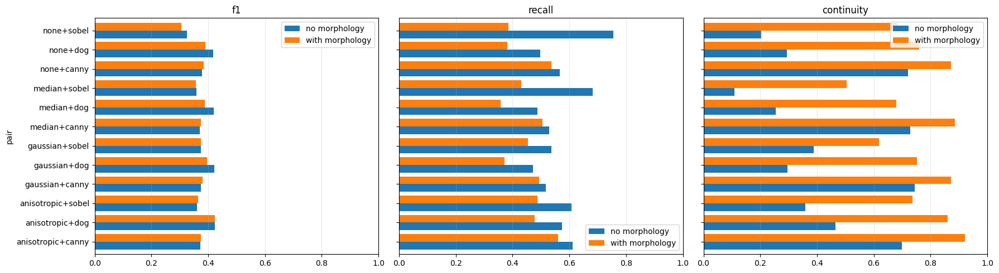

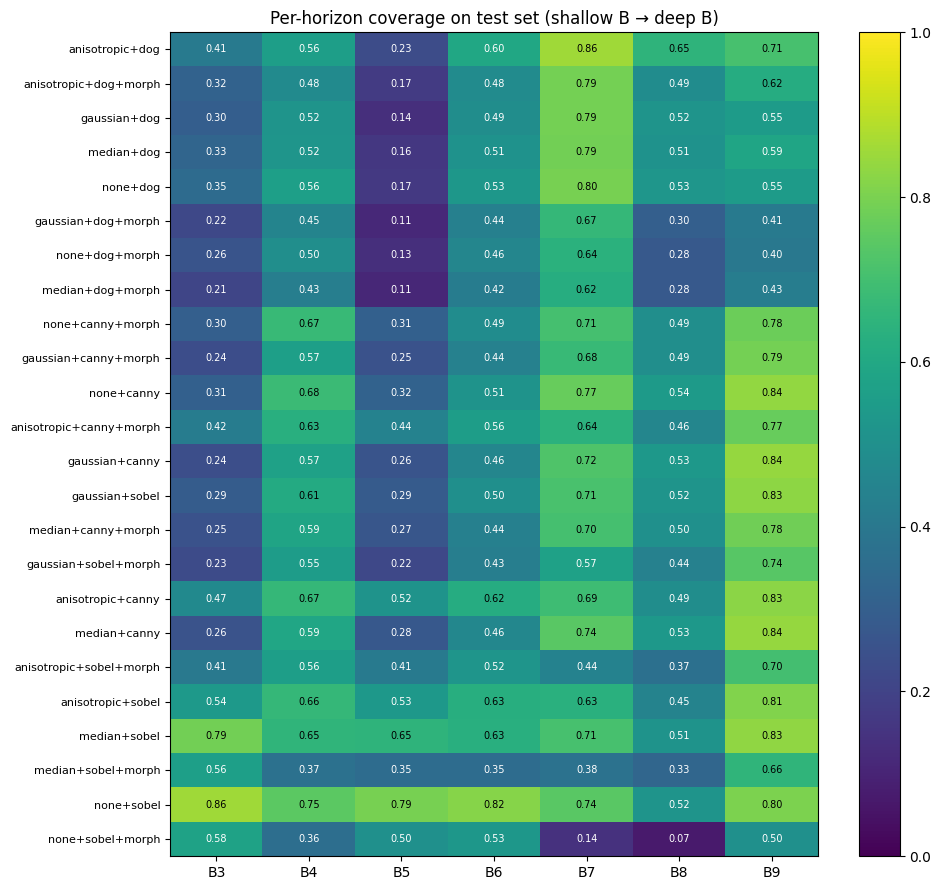

In [ ]:
# ---- F1 / recall / continuity per configuration, with and without morphology ----
m = test_df.groupby(['filter', 'detector', 'morph'])[['f1', 'recall', 'continuity']].mean().reset_index()
m['pair'] = m['filter'] + '+' + m['detector']
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, metric in zip(axes, ['f1', 'recall', 'continuity']):
    p = m.pivot(index='pair', columns='morph', values=metric)
    p.columns = ['no morphology', 'with morphology']
    p.plot.barh(ax=ax, width=0.8); ax.set_title(metric); ax.set_xlim(0, 1); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_test_bars.png'), dpi=150); plt.show()

# ---- per-horizon coverage (fraction of each horizon found within TOL) ----
cov_cols = sorted([c for c in test_df.columns if c.startswith('cov_')], key=lambda c: int(c[5:]))
cov = test_df.groupby('config')[cov_cols].mean().loc[summary.index]
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cov.values, cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(cov_cols))); ax.set_xticklabels([c[4:] for c in cov_cols])
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.index, fontsize=8)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        ax.text(j, i, f'{cov.values[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if cov.values[i, j] < 0.6 else 'black')
ax.set_title('Per-horizon coverage on test set (shallow B → deep B)'); plt.colorbar(im)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_horizon_coverage.png'), dpi=150); plt.show()

In [ ]:
# ---- statistical test: is the best configuration significantly better than the runner-up? ----
from scipy.stats import wilcoxon
best_name, second_name = summary.index[0], summary.index[1]
a = test_df[test_df.config == best_name].sort_values('section')['f1'].values
b = test_df[test_df.config == second_name].sort_values('section')['f1'].values
try:
    stat, p = wilcoxon(a, b)
    print(f'Best: {best_name}  vs  {second_name}:  mean F1 {a.mean():.3f} vs {b.mean():.3f},  Wilcoxon p = {p:.4f}')
except ValueError as err:
    print('Wilcoxon not applicable:', err)
BEST = next(c for c in CONFIGS if c['name'] == best_name)
print('Best configuration:', json.dumps(BEST, indent=1))

Best: anisotropic+dog  vs  anisotropic+dog+morph:  mean F1 0.424 vs 0.424,  Wilcoxon p = 0.6102
Best configuration: {
 "name": "anisotropic+dog",
 "filter": "anisotropic",
 "fparams": {
  "n_iter": 20,
  "kappa_pct": 90
 },
 "detector": "dog",
 "dparams": {
  "sigma": 1.5,
  "top_pct": 10,
  "polarity": "peak"
 },
 "morph": null
}


## 7. Visual comparison: every stage of the best configuration on one test section
In the final panel, **red** = interpreted horizon, **cyan** = detected horizon, **yellow** = overlap.

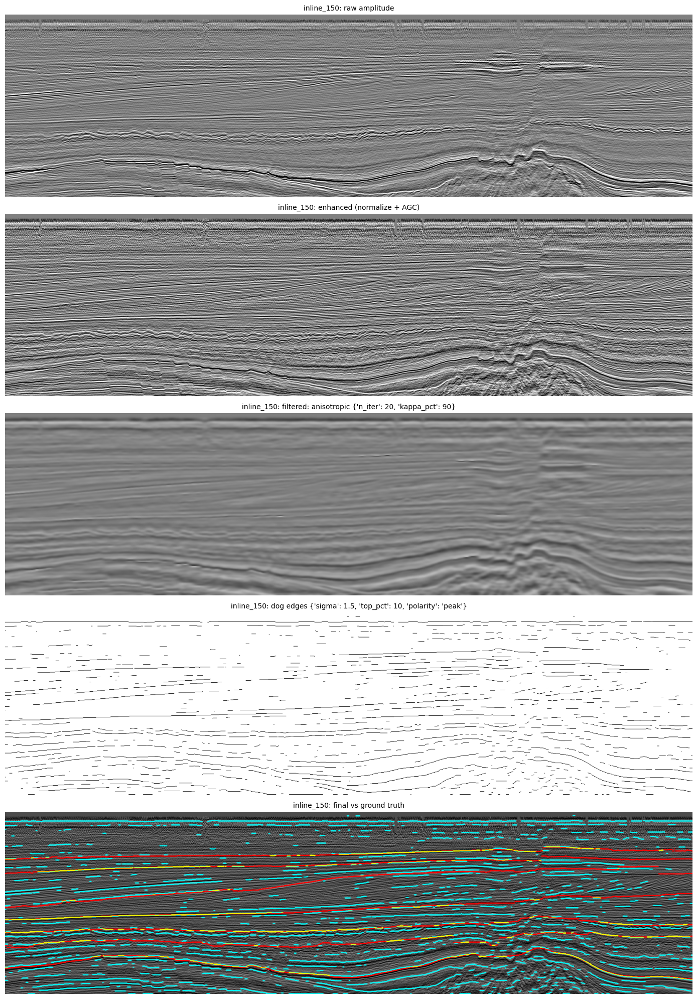

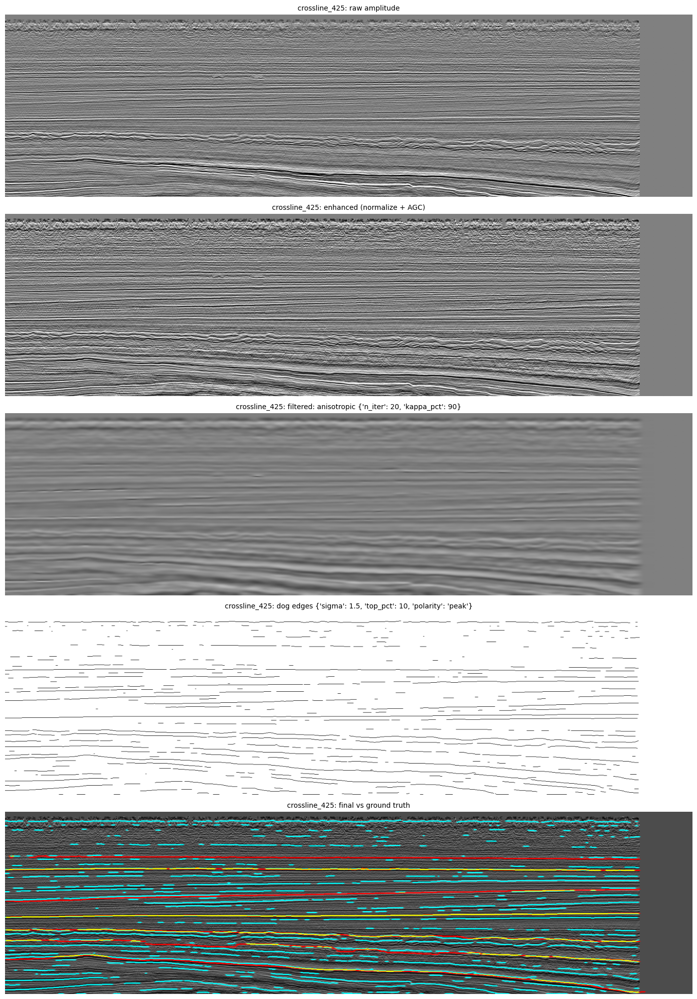

In [ ]:
def show_stages(s, cfg, fn):
    x_enh = H.enhance(s['img'], **ENH)
    x_f = H.FILTERS[cfg['filter']](x_enh, **cfg['fparams'])
    e_raw = H.DETECTORS[cfg['detector']](x_f, **cfg['dparams'])
    e = H.postprocess(e_raw, **cfg['morph']) if cfg['morph'] else e_raw
    v = np.percentile(np.abs(s['img']), 99)
    g = (np.clip(x_enh, -1, 1) + 1) / 2 * 0.6
    rgb = np.dstack([g, g, g])
    gt_d = ndi.binary_dilation(s['gt'], iterations=1); e_d = ndi.binary_dilation(e, iterations=1)
    rgb[gt_d] = [1, 0, 0]; rgb[e_d] = [0, 1, 1]; rgb[gt_d & e_d] = [1, 1, 0]
    panels = [('raw amplitude', s['img'], dict(cmap='gray', vmin=-v, vmax=v)),
              ('enhanced (normalize + AGC)', x_enh, dict(cmap='gray', vmin=-1, vmax=1)),
              (f"filtered: {cfg['filter']} {cfg['fparams']}", x_f, dict(cmap='gray', vmin=-1, vmax=1)),
              (f"{cfg['detector']} edges {cfg['dparams']}", e_raw, dict(cmap='gray_r')),
              ('final vs ground truth' + (' (after morphology)' if cfg['morph'] else ''), rgb, {})]
    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 4 * len(panels)))
    for ax, (title, im, kw) in zip(axes, panels):
        ax.imshow(im, aspect='auto', **kw); ax.set_title(f"{s['name']}: {title}", fontsize=10); ax.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, fn), dpi=130); plt.show()

show_stages(test_set[0], BEST, 'fig_stages_best_inline.png')
show_stages(test_set[len(TEST['inline'])], BEST, 'fig_stages_best_crossline.png')

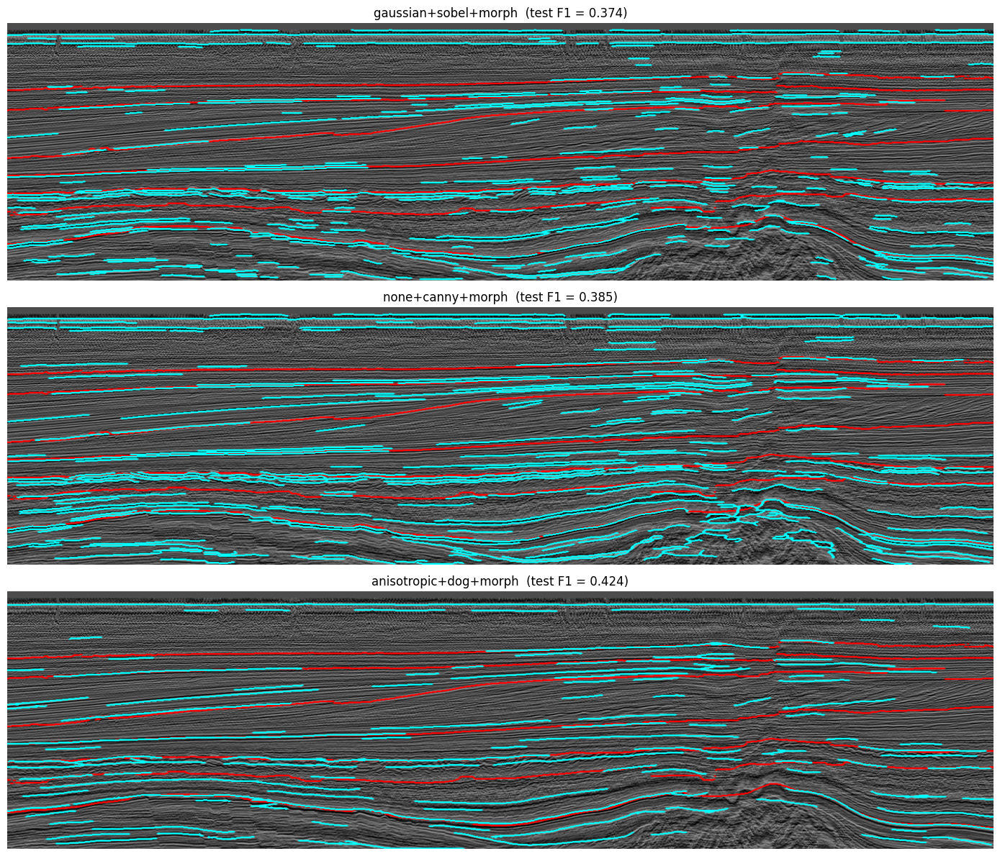

In [ ]:
# ---- same section, all three detectors (each with its best filter + morphology) side by side ----
s = test_set[0]
best_per_det = (test_df[test_df.morph].groupby(['detector', 'config']).f1.mean()
                .reset_index().sort_values('f1').groupby('detector').tail(1))
fig, axes = plt.subplots(len(best_per_det), 1, figsize=(14, 4 * len(best_per_det)))
for ax, (_, r) in zip(np.atleast_1d(axes), best_per_det.iterrows()):
    cfg = next(c for c in CONFIGS if c['name'] == r['config'])
    e, _ = H.run_pipeline(s['img'], enh=ENH, filt=(cfg['filter'], cfg['fparams']),
                          det=(cfg['detector'], cfg['dparams']), morph=cfg['morph'])
    g = (np.clip(s['enh'], -1, 1) + 1) / 2 * 0.6
    rgb = np.dstack([g, g, g])
    rgb[ndi.binary_dilation(s['gt'])] = [1, 0, 0]; rgb[ndi.binary_dilation(e)] = [0, 1, 1]
    ax.imshow(rgb, aspect='auto'); ax.axis('off'); ax.set_title(f"{cfg['name']}  (test F1 = {r['f1']:.3f})")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_detectors_compared.png'), dpi=130); plt.show()

## 8. Morphological sensitivity analysis
How the structuring-element length and angle range trade off bridging gaps (continuity ↑) against false connections
(precision ↓). Uses the tuning-stage results for the best (filter, detector) pair.

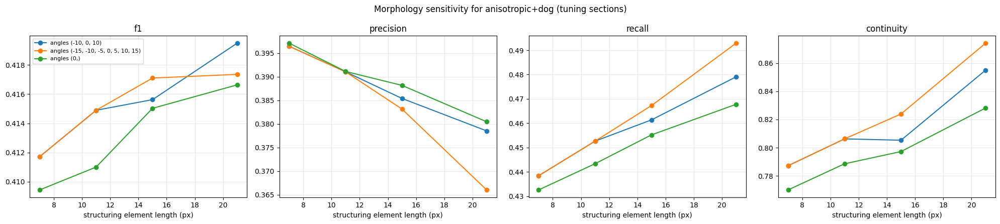

In [ ]:
pair_morph = best_morph[(best_morph['filter'] == BEST['filter'])
                        & (best_morph['detector'] == BEST['detector'])].iloc[0]['mparams']
sub = tuneB[(tuneB['filter'] == BEST['filter']) & (tuneB['detector'] == BEST['detector'])
            & (tuneB['min_extent'] == pair_morph['min_extent'])]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, metric in zip(axes, ['f1', 'precision', 'recall', 'continuity']):
    for ang, g in sub.groupby('angles'):
        ax.plot(g['length'], g[metric], 'o-', label=f'angles {ang}')
    ax.set_xlabel('structuring element length (px)'); ax.set_title(metric); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.suptitle(f"Morphology sensitivity for {BEST['filter']}+{BEST['detector']} (tuning sections)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_morph_sensitivity.png'), dpi=150); plt.show()

## 9. Enhancement ablation
Effect of the enhancement stage on the best configuration (test set). Note: the other parameters were tuned with the
default enhancement (normalize + AGC).

In [ ]:
ENH_VARIANTS = {'normalize only': dict(agc_win=0), 'normalize + AGC (default)': dict(agc_win=31),
                'normalize + AGC + CLAHE': dict(agc_win=31, use_clahe=True), 'normalize + CLAHE': dict(agc_win=0, use_clahe=True)}
rows = []
for vname, enh in ENH_VARIANTS.items():
    for s in test_set:
        e, _ = H.run_pipeline(s['img'], enh=enh, filt=(BEST['filter'], BEST['fparams']),
                              det=(BEST['detector'], BEST['dparams']), morph=BEST['morph'])
        rows.append(dict(enhancement=vname, **H.evaluate(e, s['gt'], s['hid'], tol=TOL)))
enh_df = pd.DataFrame(rows).groupby('enhancement')[METRICS].mean().round(3)
enh_df.to_csv(os.path.join(RESULTS_DIR, 'enhancement_ablation.csv')); enh_df

,precision,recall,f1,comp_precision,continuity
enhancement,,,,,
normalize + AGC (default),0.337,0.575,0.424,0.231,0.465
normalize + AGC + CLAHE,0.322,0.544,0.404,0.218,0.440
normalize + CLAHE,0.340,0.569,0.424,0.238,0.503
normalize only,0.354,0.556,0.432,0.250,0.553


## 10. Synthetic experiment: robustness to noise
Synthetic sections (Ricker wavelet, 30 Hz, 4 ms) with exactly known interfaces, at decreasing signal-to-noise ratio.
Here every interface is labelled, so precision is meaningful too.

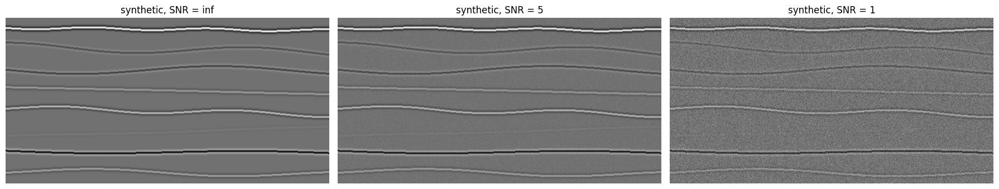

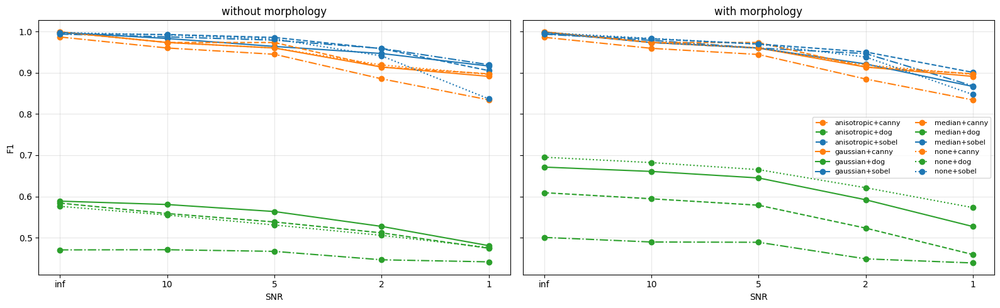

snr,inf,10,5,2,1
config,,,,,
anisotropic+dog,0.471,0.471,0.467,0.447,0.442
anisotropic+dog+morph,0.501,0.490,0.489,0.449,0.439
gaussian+dog,0.589,0.581,0.564,0.527,0.481
median+dog,0.584,0.559,0.538,0.512,0.474
none+dog,0.576,0.555,0.531,0.506,0.476
gaussian+dog+morph,0.671,0.661,0.645,0.592,0.527
none+dog+morph,0.695,0.682,0.665,0.621,0.573
median+dog+morph,0.609,0.594,0.579,0.523,0.459
none+canny+morph,0.999,0.973,0.960,0.919,0.896


In [ ]:
SNRS = [None, 10, 5, 2, 1]
SEEDS = range(2 if QUICK else 5)
syn = [(snr, seed) + H.make_synthetic(snr=snr, seed=seed) for snr in SNRS for seed in SEEDS]

fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, snr in zip(axes, [None, 5, 1]):
    img = next(x[2] for x in syn if x[0] == snr)
    ax.imshow(img, cmap='gray', aspect='auto'); ax.set_title(f'synthetic, SNR = {snr or "inf"}'); ax.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_synthetic_examples.png'), dpi=130); plt.show()

rows = []
for cfg in CONFIGS:
    for snr, seed, img, gt, lbl in syn:
        e, _ = H.run_pipeline(img, enh=ENH, filt=(cfg['filter'], cfg['fparams']),
                              det=(cfg['detector'], cfg['dparams']), morph=cfg['morph'])
        rows.append(dict(config=cfg['name'], filter=cfg['filter'], detector=cfg['detector'],
                         morph=cfg['morph'] is not None, snr='inf' if snr is None else str(snr),
                         **H.evaluate(e, gt, tol=TOL)))
syn_df = pd.DataFrame(rows)
syn_df.to_csv(os.path.join(RESULTS_DIR, 'synthetic_results.csv'), index=False)

order = ['inf'] + [str(s) for s in SNRS[1:]]
colors = {'sobel': 'tab:blue', 'canny': 'tab:orange', 'dog': 'tab:green'}
styles = {'none': ':', 'gaussian': '-', 'median': '--', 'anisotropic': '-.'}
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, use_m in zip(axes, (False, True)):
    g = syn_df[syn_df.morph == use_m].groupby(['filter', 'detector', 'snr']).f1.mean().reset_index()
    for (f, d), gg in g.groupby(['filter', 'detector']):
        gg = gg.set_index('snr').loc[order]
        ax.plot(order, gg['f1'], styles[f], color=colors[d], marker='o', label=f'{f}+{d}')
    ax.set_title('with morphology' if use_m else 'without morphology'); ax.set_xlabel('SNR'); ax.grid(alpha=0.3)
axes[0].set_ylabel('F1'); axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'fig_synthetic_f1_vs_snr.png'), dpi=150); plt.show()
syn_df.groupby(['config', 'snr']).f1.mean().unstack()[order].loc[summary.index].round(3)

## 11. Runtime per stage (best configuration, test set)

In [ ]:
rt = test_df[test_df.config == best_name][['ms_enhance', 'ms_filter', 'ms_detect', 'ms_morph', 'ms_total']]
rt = rt.agg(['mean', 'std']).T.round(1); rt.columns = ['mean (ms)', 'std (ms)']
rt.to_csv(os.path.join(RESULTS_DIR, 'runtime_best.csv'))
print(f'All results and figures saved to {RESULTS_DIR}')
rt

All results and figures saved to /content/drive/MyDrive/F3_dataset/results


,mean (ms),std (ms)
ms_enhance,30.4,4.1
ms_filter,224.9,29.6
ms_detect,34.2,4.8
ms_morph,0.0,0.0
ms_total,289.5,31.4
